# The "World Model": Predicting Air Pollution from Electricity Generation, Using All Countries

**The question:** Can we predict how polluted a country's air is from how it generates its electricity?

**What is this notebook for?** It builds the **world model**: one model trained on data from *every* country. Other, separate **regional models** (Americas, Europe, Asia, Australia) are in other notebooks. The world model is the **benchmark**.

**The plan**

1. **Look at the data** before doing anything with it.
2. **Split by time:** learn from the past (before 2018), then be tested on the "future" (2018 onwards), like a real forecast.
3. **Compare a few models** (straight-line models and a Random Forest) fairly, using a technique called *cross-validation*.
4. **Pick the best one and test it once** on the future data.
5. **Save** the numbers, the model and the charts so teammates can reuse them.
6. **Which inputs actually help?** (Part 6): remove groups of features one at a time to see which ones the model really needs.
7. **A second question** (Part 7): when a country *changes* its electricity generation, does its own air quality change?

Run it from top to bottom with **Run All**, or one cell at a time with **Shift + Enter**.

### Key terms
| Term | Meaning |
|---|---|
| **PM2.5** | Tiny airborne particles that are harmful to breathe, in micrograms per cubic metre (µg/m³). Lower is better. This is what we **predict** (the *target*). |
| **Features** | The inputs the model uses. Here, all features describe **electricity generation** and **what power plants emit** (see Steps 1b and 1c). |
| **Emissions vs exposure** | **Exposure** (our target) is the PM2.5 that people actually breathe, measured in the air. **Emissions** are the pollutants released at the source, such as a power-plant chimney. Emissions go in as inputs; exposure is what we predict. They are different things: wind carries pollution between countries, and some pollution forms in the air after release. |
| **SO₂ (sulphur dioxide)** | A gas released mainly when coal and oil are burned. In the air it turns into fine **sulphate** particles, which count as PM2.5. |
| **NOx (nitrogen oxides)** | Gases released when any fuel is burned at high temperature (power plants, vehicles). In the air they turn into fine **nitrate** particles, which count as PM2.5. |
| **Secondary particles** | PM2.5 that forms **in the air** from gases such as SO₂ and NOx, rather than leaving a chimney as particles. This is why SO₂ and NOx matter for PM2.5 even though they aren't particles themselves. |
| **EDGAR** | *Emissions Database for Global Atmospheric Research*, run by the European Commission's Joint Research Centre. It **estimates** (not measures) each country's yearly emissions of each pollutant, broken down by sector (power, transport, industry, homes, etc.). |
| **Power sector** | EDGAR's category *"Main Activity Electricity and Heat Production"*: emissions from power stations (and heat plants). It leaves out transport, industry, homes and everything else. |
| **Gg** | Gigagram = a thousand tonnes. The unit EDGAR uses. We convert it to grams per kWh and kilograms per person. |
| **kWh / TWh** | A **kilowatt-hour** is a unit of electrical energy (one kettle running for about half an hour). A **terawatt-hour** is a billion kWh. "Per kWh" means "for each unit of electricity generated". |
| **Per kWh vs per person** | **Per kWh** shows how *dirty* each unit of electricity is (reflects filters and scrubbers). **Per person** shows how *much* pollution there is relative to the population. A big country emits more in total, so totals alone aren't comparable between countries. |
| **ISO code** | The standard 3-letter country code (e.g. AUS for Australia). We join datasets on it because country *names* are spelled differently between sources. |
| **Regression** | A model that predicts a *number* (here, a PM2.5 level) rather than a category. |
| **Data leakage** | Accidentally letting the model "peek" at information it wouldn't have in real life. This makes results look better than they really are. Much of the care below is about preventing it. |
| **Ablation** | Removing one group of inputs at a time and re-scoring, to see how much each group really contributes. If the score barely changes when a group is removed, the model didn't need it. |
| **Feature set** | A named group of inputs. We compare the **original** two shares, **C** (shares + per-person electricity) and **D** (C + power-plant emissions). |
| **Within-country (Part 7)** | Comparing a country with **itself** over time instead of with other countries. Each value is turned into a **deviation**: this year minus that country's own average. |


> ### Changes from the original plan (7 October 2026)
>
> **Original plan:** the model used only **two features**: the % of electricity from greenhouse-gas-emitting sources (coal, gas, oil) and the % from non-emitting sources (solar, wind, hydro, nuclear, etc.).
>
> **What we found:** those two numbers add up to about 100%, so they really carry only *one* piece of information. With them, every model (straight-line and Random Forest) scored an R² of about 0, meaning it was no better than predicting the world average for every country.
>
> **Change 1 - feature set C:** more columns from the *same* electricity dataset (no new data sources):
> - each source's share **separately** (coal, gas, oil, hydro, nuclear, solar, wind, biofuel), because coal pollutes far more than gas, which the two-bucket version hid; and
> - **per-person** electricity amounts (coal, gas, oil and fossil electricity per person, and total electricity per person), because *how much* coal is burned matters, not only its share.
>
> **Change 2 - feature set D:** feature set C **plus what power plants actually emit**, from the EDGAR v8.1 air pollutant inventory (European Commission): sulphur dioxide (SO₂), nitrogen oxides (NOx) and fine particles (PM2.5) released by power plants, per kWh generated and per person. The reasoning was that electricity shares alone can't tell a coal plant with pollution filters from one without, and that SO₂ and NOx should matter most because they turn into PM2.5 in the air (see the background table below).
>
> **Correction (9 October 2026): Part 6 did not support the expectation that SO₂ and NOx matter most.** Removing all the power-plant emission features lowers cross-validation R² by only about 0.03, which is within the noise between folds. Direct PM2.5 contributed the most of the three and SO₂ and NOx very little. The chemistry is real, but in this data it does not show up as better predictions. Feature set D was kept because it has the lowest cross-validation error, not because the evidence for the emission features is strong.
>
> **Change 3 - new Part 6:** an **ablation** that removes one group of features at a time to show which ones really help, and tests whether the per-person group is just a stand-in for national wealth.
>
> **Change 4 - new Part 7:** a second analysis that compares each country **with itself over time**, instead of comparing countries with each other. This asks a different question from the rest of the notebook, so it comes last.
>
> **All three feature sets (original, C, D) are kept and compared side by side**, so the effect of each change is visible and the original plan's result is still reported.
>
> **Caveat:** electricity use per person is also a rough sign of how **wealthy** a country is, and wealthier countries tend to have cleaner air for many reasons (not only electricity). Part of any improvement may come from that. Part 6 tests this directly.

## Background: what do power plants emit?

PM2.5 is **not** the only pollutant from power generation, and for most power plants it isn't even the main way they affect PM2.5 levels:

| Generation method | Main air pollutants while operating | Notes |
|---|---|---|
| **Coal** | **SO₂** (sulphur dioxide), **NOx** (nitrogen oxides), **PM2.5/PM10** (fly ash), mercury and other heavy metals, CO₂ | The most polluting source. Dust filters capture most fly ash; only dedicated *scrubbers* remove SO₂. |
| **Oil** | **SO₂** (high for heavy fuel oil), **NOx**, PM, metals (e.g. vanadium, nickel), CO₂ | Common on islands and in some oil-producing countries. |
| **Natural gas** | **NOx**, CO₂ | Very little SO₂ or PM. Methane can leak upstream (a greenhouse gas). |
| **Biomass / biofuel** | **PM2.5**, NOx, CO, organic compounds | Burning wood or crop waste produces a lot of particles. |
| **Nuclear** | None from operation | Issues are radioactive waste and mining, not air pollution. |
| **Hydro, wind, solar** | None from operation | Small emissions during manufacturing and construction. |

**Why SO₂ and NOx matter for PM2.5:** most of the PM2.5 caused by power plants does *not* leave the chimney as particles. SO₂ and NOx gases react in the air downwind and form fine **sulphate** and **nitrate** particles, which count as PM2.5. These are called *secondary* particles. So a plant that emits little PM2.5 directly can still cause a lot of PM2.5 exposure. This is why feature set D includes SO₂ and NOx, not just PM2.5. Whether they improve prediction in practice is tested in Part 6.

## Step 0 - Load the tools and settings

All the settings are defined in one place here, so you can change them without hunting through the code.

Notes on a few choices:

- **`RANDOM_STATE = 42`** - anything random in the code uses this fixed seed, so everyone who runs the notebook gets the same results.
- **`SPLIT_YEAR = 2018`** - rows **before** 2018 are for learning; rows from **2018 on** are the final exam. 2018 was chosen because it gives close to the usual 80% / 20% split between learning and testing.
- **`FEATURE_SETS`** - the three groups of inputs being compared: the **original** two shares, **feature set C** and **feature set D** (see the note above).
- **`EDGAR_FILES`** - the EDGAR emission spreadsheets in the `data/raw/` folder (reading them needs the `openpyxl` package, listed in `requirements.txt`).
- **`AGGREGATES`** - the dataset also contains rows for *groups* such as "World", "European Union (27)" and income groups. These overlap with the individual countries (the EU row is just its member countries combined), so keeping them would count the same countries twice in a "world" model. We remove them.

In [1]:
import os

import joblib
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_FILE = "../data/processed/cleaned_climate_merged.csv"
ENERGY_DATASET = "pralabhpoudel/world-energy-consumption"   # Kaggle, same source as the cleaning step
EDGAR_FILES = {   # EDGAR v8.1 air pollutant emissions, Gg (thousand tonnes) per year
    "so2": "../data/raw/EDGAR_SO2_1970_2022.xlsx",
    "nox": "../data/raw/EDGAR_NOx_1970_2022.xlsx",
    "pm25": "../data/raw/EDGAR_PM2.5_1970_2022.xlsx",
}
POWER_SECTOR = "1.A.1.a"   # EDGAR/IPCC code for "Main Activity Electricity and Heat Production" it's used to pick out only power-plant rows.
OUT_DIR = "../results"   # notebooks run from the notebooks/ folder
TARGET = "PM2.5 Exposure"
SPLIT_YEAR = 2018   # Train on years before this, test on years from it on. This gave 83% / 17%.
N_FOLDS = 5
TEST_COUNTRY = "Australia"

# Original plan: two shares that add up to ~100%.
ORIGINAL_FEATURES = ["% GHG emitting source", "% GHG non emitting source"]
# Change 1 - feature set C: electricity-generation columns from the same energy dataset.
SOURCE_SHARES = ["coal_share_elec", "gas_share_elec", "oil_share_elec", "hydro_share_elec",
                 "nuclear_share_elec", "solar_share_elec", "wind_share_elec", "biofuel_share_elec"]
# Per capita means per person.
PER_PERSON = ["coal_elec_per_capita", "gas_elec_per_capita", "oil_elec_per_capita",
              "fossil_elec_per_capita", "per_capita_electricity"]
# Change 2 - feature set D: C + power-plant emissions from EDGAR.
POWER_EMISSIONS = []   # e.g. "power_so2_per_kwh", "power_so2_per_capita", ...


# per_kwh is how dirty each unit of electricity is 
# per_capita is how much power-plant pollution there is relative to the population.
for pollutant in EDGAR_FILES:
    for unit in ["per_kwh", "per_capita"]:
        POWER_EMISSIONS.append(f"power_{pollutant}_{unit}")
        print(f"power_{pollutant}_{unit}")

FEATURE_SETS = {
    "Original (2 shares)": ORIGINAL_FEATURES,
    "C (shares + per-person)": SOURCE_SHARES + PER_PERSON,
    "D (C + power-plant emissions)": SOURCE_SHARES + PER_PERSON + POWER_EMISSIONS,
}

# Regions/income groups in the source data. They overlap with the individual countries,
# so keeping them would double-count in a "world" model.
AGGREGATES = [
    "World", "European Union (27)", "High-income countries", "Upper-middle-income countries",
    "Lower-middle-income countries", "Low-income countries",
]

os.makedirs(OUT_DIR, exist_ok=True)

C:\Users\baraa\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


power_so2_per_kwh
power_so2_per_capita
power_nox_per_kwh
power_nox_per_capita
power_pm25_per_kwh
power_pm25_per_capita


# Part 1 - Look at the data first

## Step 1 - Load and inspect

Before modelling we check what we actually have: how many rows, which columns, whether anything is missing, how many years and countries. Each row is one country in one year.

Then we remove the aggregate rows described above.

- df["country"].isin(AGGREGATES): A True/False for each row: is this one of the 6 grouping names?
- ~	NOT: it flips every True to False and vice versa. So now True means “this is a real country”.
- df[ ... ]	Boolean filtering (from Notebook 1): keep only the rows marked True.
- .reset_index(drop=True): Renumber the rows from 0 again.

In [ ]:
df = pd.read_csv(DATA_FILE)
print(f"Shape: {df.shape}")
# .nunique() counts unique values, so it gives the number of distinct countries rather than the number of rows.
print(f"Years: {df.year.min()}-{df.year.max()}, countries/regions: {df.country.nunique()}")
print(f"Missing values per column:\n{df.isna().sum()}\n")

# drop the Regions/income columns from the source data
df = df[~df["country"].isin(AGGREGATES)].reset_index(drop=True) 
print(f"After dropping aggregates: {df.shape[0]} rows, {df.country.nunique()} countries")

Shape: (4997, 5)
Years: 1990-2022, countries/regions: 196
Missing values per column:
country                      0
year                         0
% GHG emitting source        0
% GHG non emitting source    0
PM2.5 Exposure               0
dtype: int64

After dropping aggregates: 4810 rows, 190 countries


## Step 1b - Add the extra electricity columns for feature set C *(change 1)*

The cleaned file only keeps the two summary shares. The extra columns for feature set C come from the **same** World Energy Consumption dataset used to build the cleaned file, so we download it again and attach its columns to each country-year row.

| Feature | What it measures |
|---|---|
| `coal_share_elec`, `gas_share_elec`, `oil_share_elec` | % of the country's electricity from coal, gas and oil (the polluting sources), each counted separately |
| `hydro_share_elec`, `nuclear_share_elec`, `solar_share_elec`, `wind_share_elec`, `biofuel_share_elec` | % from each cleaner source, separately |
| `coal_elec_per_capita`, `gas_elec_per_capita`, `oil_elec_per_capita` | Electricity made from coal / gas / oil **per person** (kWh) |
| `fossil_elec_per_capita` | Electricity from all fossil fuels per person (kWh) |
| `per_capita_electricity` | Total electricity generated per person (kWh) |

We also keep `iso_code` (the 3-letter country code, e.g. AUS), `population` and `electricity_generation` (TWh) from this dataset. They aren't model inputs; they're needed in the next step to match and scale the EDGAR emissions.

A few of these have gaps (for example, nuclear and biofuel shares are missing for some country-years). We **don't** fill the gaps here. They are filled inside the model Pipeline (Step 3a), so the filling is learned from the training data only.

In [3]:
energy_path = kagglehub.dataset_download(ENERGY_DATASET)
energy = pd.read_csv(os.path.join(energy_path, "World Energy Consumption.csv"))

energy_cols = SOURCE_SHARES + PER_PERSON + ["iso_code", "population", "electricity_generation"]
n_before = len(df)
df = df.merge(energy[["country", "year"] + energy_cols], on=["country", "year"], how="left")
assert len(df) == n_before, "merge should not add or drop rows"

print("Missing values in the new columns (% of rows):")
print((df[SOURCE_SHARES + PER_PERSON].isna().mean() * 100).round(1).to_string())

Missing values in the new columns (% of rows):
coal_share_elec           0.0
gas_share_elec            0.0
oil_share_elec            0.0
hydro_share_elec          0.5
nuclear_share_elec        3.2
solar_share_elec          0.0
wind_share_elec           0.0
biofuel_share_elec        4.9
coal_elec_per_capita      0.0
gas_elec_per_capita       0.0
oil_elec_per_capita       0.0
fossil_elec_per_capita    0.0
per_capita_electricity    0.0


## Step 1c - Add power-plant emissions for feature set D *(change 2)*

The EDGAR spreadsheets list each country's yearly emissions **by sector**. We keep only the power sector (*"Main Activity Electricity and Heat Production"*), adding together its fossil-fuel and biofuel parts, for three pollutants: **SO₂, NOx and PM2.5**.

We then turn the totals (in thousand tonnes) into two kinds of feature per pollutant, because a big country naturally emits more than a small one:

| Feature | What it measures | Why |
|---|---|---|
| `power_so2_per_kwh`, `power_nox_per_kwh`, `power_pm25_per_kwh` | Grams emitted per kWh of electricity generated | **How dirty** each unit of electricity is. This reflects pollution controls (filters, scrubbers), which the electricity shares can't show. |
| `power_so2_per_capita`, `power_nox_per_capita`, `power_pm25_per_capita` | Kilograms emitted per person per year | **How much** power-plant pollution there is relative to the population. |

Countries are matched on their 3-letter code (e.g. AUS), not their name, because EDGAR spells some names differently (e.g. "Viet Nam").

| Conversion | Why |
|---|---|
| electricity_generation × 1e9 | 1 TWh = 10⁹ kWh |
| gg × 1e9 → grams | 1 Gg (thousand tonnes) = 10⁹ g |
| gg × 1e6 → kilograms | 1 Gg = 10⁶ kg |
--------------
> **Known gaps:** about 4% of rows have no EDGAR power-sector entry. Many are countries that get almost all their electricity from hydro or imports (e.g. Nepal, Paraguay, Laos), whose real value is probably close to 0; a few (e.g. Serbia, Montenegro) are probably grouped differently in EDGAR. These gaps are left to the Pipeline, which fills them with the median value. Also, EDGAR's power sector includes heat plants, so per-kWh values are slightly overstated in countries with a lot of district heating.

In [ ]:
def power_sector_emissions(path, name):
    """One pollutant's yearly power-sector emissions per country (Gg), from an EDGAR spreadsheet."""
    sheet = pd.read_excel(path, sheet_name="IPCC 2006", header=9)   # first 9 rows are a title block
    power = sheet[sheet["ipcc_code_2006_for_standard_report"] == POWER_SECTOR]
    # collects every column whose name starts with "Y_". str(c) guards against non-text column names
    year_cols = [c for c in power.columns if str(c).startswith("Y_")]

    # Wide format has one column per year. Long format has one row per country-year, which is the shape our main table df has. .melt converts between them.
    # id_vars are the columns that stay as identifiers.
    # value_vars are the columns to unpivot.
    # var_name is the new column that holds the old column names.
    # value_name is the new column that holds the numbers, here power_so2_gg and so on.
    long = power.melt(id_vars="Country_code_A3", value_vars=year_cols, var_name="year", value_name=name)
    # dropping Y_
    long["year"] = long["year"].str[2:].astype(int)
    # add the fossil and biofuel rows together for each country-year (because we dont't care about fuel type, the clusters are pollutatnt type!)
    return (long.groupby(["Country_code_A3", "year"], as_index=False)[name].sum(min_count=1)
                .rename(columns={"Country_code_A3": "iso_code"}))


generation_kwh = df["electricity_generation"] * 1e9   # TWh -> kWh
for pollutant, path in EDGAR_FILES.items():
    gg = f"power_{pollutant}_gg"
    df = df.merge(power_sector_emissions(path, gg), on=["iso_code", "year"], how="left")
    df[f"power_{pollutant}_per_kwh"] = (df[gg] * 1e9 / generation_kwh.where(generation_kwh > 0))  # g per kWh
    df[f"power_{pollutant}_per_capita"] = df[gg] * 1e6 / df["population"]                       # kg per person
assert len(df) == n_before, "merge should not add or drop rows"

print("Missing values in the new columns (% of rows):")
print((df[POWER_EMISSIONS].isna().mean() * 100).round(1).to_string())
df[POWER_EMISSIONS].describe().round(2)

Missing values in the new columns (% of rows):
power_so2_per_kwh        4.3
power_so2_per_capita     4.3
power_nox_per_kwh        4.3
power_nox_per_capita     4.3
power_pm25_per_kwh       4.3
power_pm25_per_capita    4.3


,power_so2_per_kwh,power_so2_per_capita,power_nox_per_kwh,power_nox_per_capita,power_pm25_per_kwh,power_pm25_per_capita
count,4602.00,4602.00,4602.00,4602.00,4602.00,4602.00
mean,4.88,9.59,2.90,4.39,0.15,0.24
std,5.60,19.99,4.00,6.17,0.29,0.46
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.47,0.63,0.58,0.72,0.03,0.03
50%,3.29,2.94,1.47,2.15,0.06,0.10
75%,7.17,10.32,3.56,5.53,0.15,0.26
max,49.16,300.05,46.37,75.15,3.70,7.74


## Step 1d - How much of PM2.5 actually comes from power plants?

Before modelling, it's worth knowing how much we can expect electricity to explain. EDGAR's PM2.5 spreadsheet covers **every** sector, so we can work out the power sector's share of the PM2.5 emitted directly.

Keep in mind this undercounts power plants a little (their SO₂ and NOx later turn into extra PM2.5 in the air) and it leaves out natural sources such as desert dust, which EDGAR doesn't record.
| before .unstack | after |   |   |
| --- | --- | --- | --- |
| (AUS, Power) → 4 |   | Power | Residential |
| (AUS, Residential) → 6 | AUS | Power | Residential |
| (NZL, Power) → 1 | NZL | Power | Residential |

In [ ]:
all_sectors = pd.read_excel(EDGAR_FILES["pm25"], sheet_name="IPCC 2006", header=9)
sector_name = "ipcc_code_2006_for_standard_report_name"
YEAR_COL = f"Y_{SPLIT_YEAR - 1}"   # the last training year

world = all_sectors.groupby(sector_name)[YEAR_COL].sum().sort_values(ascending=False)
print(f"World PM2.5 emissions by sector, {YEAR_COL[2:]} (% of total):")
print((world / world.sum() * 100).round(1).head(6).to_string())

# .unstack. Grouping by two columns gives a Series with a two-level label (country, sector). 
# .unstack moves the inner level (sector) into columns
by_country = all_sectors.groupby(["Country_code_A3", sector_name])[YEAR_COL].sum().unstack(fill_value=0)

# calcualtes the percentage
power_share = by_country["Main Activity Electricity and Heat Production"] / by_country.sum(axis=1) * 100
print(f"\nPower plants' share of a country's PM2.5 emissions: median country {power_share.median():.1f}%, "
      f"Australia {power_share.get('AUS', np.nan):.1f}%")

World PM2.5 emissions by sector, 2017 (% of total):
ipcc_code_2006_for_standard_report_name
Residential and other sectors                    33.3
Manufacturing Industries and Construction        24.0
Emissions from biomass burning                   12.6
Water-borne Navigation                            6.4
Main Activity Electricity and Heat Production     4.6
Cement production                                 3.4

Power plants' share of a country's PM2.5 emissions: median country 4.1%, Australia 4.0%


> **What this means:** power plants are only a small slice of directly emitted PM2.5 (most comes from homes burning wood, coal or charcoal, from industry and from fires). So even a perfect electricity-based model can explain only part of the differences in air pollution between countries. A modest score below is **an expected result, not a failure**.

In [6]:
df.head()

,country,year,% GHG emitting source,% GHG non emitting source,PM2.5 Exposure,coal_share_elec,gas_share_elec,oil_share_elec,hydro_share_elec,nuclear_share_elec,...,electricity_generation,power_so2_gg,power_so2_per_kwh,power_so2_per_capita,power_nox_gg,power_nox_per_kwh,power_nox_per_capita,power_pm25_gg,power_pm25_per_kwh,power_pm25_per_capita
0,Afghanistan,2000,34.043,65.957,48.754530,0.0,0.0,34.043,65.957,0.0,...,0.47,3.481150,7.406703,0.178128,1.850316,3.936842,0.094679,0.042841,0.091151,0.002192
1,Afghanistan,2001,15.254,84.746,47.343914,0.0,0.0,15.254,84.746,0.0,...,0.59,4.055020,6.872915,0.205957,1.938747,3.286012,0.098470,0.114816,0.194604,0.005832
2,Afghanistan,2002,18.841,81.159,49.618782,0.0,0.0,18.841,81.159,0.0,...,0.69,3.642480,5.278956,0.173449,1.762968,2.555026,0.083950,0.096618,0.140026,0.004601
3,Afghanistan,2003,32.979,67.021,48.647667,0.0,0.0,32.979,67.021,0.0,...,0.94,5.366716,5.709272,0.236992,2.496271,2.655608,0.110234,0.162604,0.172983,0.007181
4,Afghanistan,2004,37.079,62.921,47.392006,0.0,0.0,37.079,62.921,0.0,...,0.89,4.527372,5.086935,0.192216,2.282138,2.564200,0.096891,0.149201,0.167642,0.006335


# Part 2 - Splitting the data by time

## Step 2 - Learn from the past, be tested on the future

We split by **year**, not randomly:

- **Training set:** all rows **before 2018**. The model learns from these.
- **Test set:** all rows **from 2018 onwards**. This is the final exam.

The cell below also prints what share of the data ends up in each set (close to 80% / 20%).

Why by year? A random split would let the model learn from, say, Australia in 2020 and then be "tested" on Australia in 2019, which is not how real forecasting works. Splitting by time is a stricter, more honest test.

**The golden rule:** the test set is **never** used for training, tuning, scaling or filling in gaps. It is used **exactly once**, at the very end (Step 4).

In [ ]:
train = df[df["year"] < SPLIT_YEAR]
test = df[df["year"] >= SPLIT_YEAR]   # touched exactly once, at the very end
# groups_train is each row’s country name. It isn’t an input to any model. 
# It’s the label that GroupKFold uses in Step 3b to keep a country’s rows together.
y_train, groups_train = train[TARGET], train["country"]
y_test = test[TARGET]

print(f"Train: {len(train)} rows (years {train.year.min()}-{train.year.max()}), {len(train) / len(df):.0%} of the data")
print(f"Test:  {len(test)} rows (years {test.year.min()}-{test.year.max()}), {len(test) / len(df):.0%} of the data")

Train: 3971 rows (years 1990-2017), 83% of the data
Test:  839 rows (years 2018-2022), 17% of the data


# Part 3 - Comparing models fairly

## Step 3a - The candidate models

We try two kinds of model.

**Straight-line models**

- **Linear Regression (the baseline):** draws the best straight-line relationship between the inputs and PM2.5. Every other model has to beat this to be worth using.
- **Ridge Regression:**: `error + alpha × (sum of squared slopes)`. the same idea, but it discourages extreme values for the line's slopes. This helps when inputs are very similar to each other. Ours are: the two original shares add up to roughly 100%, coal share and coal-per-person move together, and SO₂ and NOx per kWh are closely linked. The `alpha` setting controls how strong that discouragement is. We try three strengths (1, 10, 100).

**A non-linear model: Random Forest**

A straight line can only say "more coal → a bit more pollution, at a constant rate". The real relationship might be bumpier, for example pollution could jump only once coal passes a certain share. A **Random Forest** can capture that.

- It is made of many **decision trees**. Each tree is a flowchart of yes/no questions ("Is the coal share above 70%?") that ends in a predicted PM2.5 value.
- Each tree is trained on a slightly different random sample of the data, so the trees make different mistakes. The forest **averages** all the trees' answers, which cancels out much of the noise (*"Randomization is Key"*).
- We set two **hyper-parameters**, i.e. settings chosen by us before training, not learned from the data:
  - `n_estimators=100`: the number of trees.
  - `max_depth`: how many questions deep each tree may go. Shallow trees (depth 5) learn broad patterns; deeper trees (depth 10) learn finer detail but risk **overfitting**, i.e. memorising the training countries instead of learning patterns that carry over. Cross-validation will tell us which works better.

**Pre-Processing: filling gaps and scaling, without leakage.** Each model is **Pre-Processed** with two preparation steps:

1. **Fill gaps** (`SimpleImputer`): a missing value is replaced by the *median* (middle value) of that column. *(Added with feature sets C and D, since some of their columns have gaps. The original two shares have none, so this step changes nothing for them.)*
2. **Scale** (`StandardScaler`): puts every input on the same scale. Ridge needs this so that a column measured in kWh per person doesn't swamp one measured in %. (Trees don't need scaling, but keeping the same Pipeline for every model makes the comparison like-for-like and does no harm.). StandardScaler rewrites each column as (value − column mean) ÷ column std, so every column ends up with a mean of 0 and a spread of 1.

Because both steps live *inside* the Pipeline, during cross-validation the median and the scale are re-learned from only the training part of each round, so nothing from the held-out part, or from the test set, sneaks in.

In [8]:
def make_pipeline(estimator):
    return Pipeline([
        ("fill_gaps", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", estimator),
    ])

models = {
    "LinearRegression": make_pipeline(LinearRegression()),
    "Ridge(alpha=1)": make_pipeline(Ridge(alpha=1.0, random_state=RANDOM_STATE)),
    "Ridge(alpha=10)": make_pipeline(Ridge(alpha=10.0, random_state=RANDOM_STATE)),
    "Ridge(alpha=100)": make_pipeline(Ridge(alpha=100.0, random_state=RANDOM_STATE)),
    "RandomForest(depth=5)": make_pipeline(
        RandomForestRegressor(n_estimators=100, max_depth=5, random_state=RANDOM_STATE, n_jobs=-1)),
    "RandomForest(depth=10)": make_pipeline(
        RandomForestRegressor(n_estimators=100, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1)),
}
list(models)

['LinearRegression',
 'Ridge(alpha=1)',
 'Ridge(alpha=10)',
 'Ridge(alpha=100)',
 'RandomForest(depth=5)',
 'RandomForest(depth=10)']

## Step 3b - Cross-validation (on the training set only)

How do we choose between models without touching the test set? With **cross-validation**:

1. Cut the training data into **5 groups ("folds")**.
2. Train on 4 folds, check the score on the 1 left-out fold.
3. Repeat 5 times so every fold gets a turn as the left-out one.
4. Report the **average** score (and the **spread**, i.e. standard deviation, which shows how stable it is).

**A twist: we group by country.** we can't use ordinary folds with our data as that would put Australia 1995-2005 in the training part and Australia 2006 in the checking part. Neighbouring years of the same country look very alike, so the model would get an unfairly easy exam. `GroupKFold` keeps **each country entirely inside one fold**, so the check is always on countries the model has *not* seen. (`StratifiedKFold` is meant for categories, so it doesn't apply to a numeric target like PM2.5.)

**Every model is tried with all three feature sets** (original, C and D), giving 18 combinations, all scored on exactly the same folds.

**The three scores:**

| Score | Meaning | Better is |
|---|---|---|
| **R²** | Share of the ups and downs in pollution the model explains. 1 = perfect, 0 = no better than always guessing the average, negative = worse than that. | Higher |
| **RMSE** | Typical size of the errors in µg/m³ (big misses count extra). | Lower |
| **MAE** | Plain average size of the errors in µg/m³. | Lower |

In [ ]:
# GroupKFold keeps every country entirely inside one fold, so a country's neighbouring years
# can't leak between train and validation (it is deterministic, so no random_state needed).
cv = GroupKFold(n_splits=N_FOLDS)
scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

def cross_validate_all(frame, target, feature_sets, candidate_models):
    """CV every model on every feature set; returns a results table and the per-fold scores."""
    rows, folds = [], {}
    for fs_name, features in feature_sets.items():
        for model_name, pipe in candidate_models.items():
            res = cross_validate(pipe, frame[features], frame[target], groups=frame["country"],
                                 cv=cv, scoring=scoring)
            folds[f"{model_name} | {fs_name}"] = {"R2": res["test_r2"], "RMSE": -res["test_rmse"],
                                                  "MAE": -res["test_mae"]}
            rows.append({
                "model": model_name, "feature_set": fs_name,
                "cv_r2_mean": res["test_r2"].mean(), "cv_r2_std": res["test_r2"].std(),
                "cv_rmse_mean": -res["test_rmse"].mean(), "cv_rmse_std": res["test_rmse"].std(),
                "cv_mae_mean": -res["test_mae"].mean(), "cv_mae_std": res["test_mae"].std(),
            })
    # converts a list of dictionaries into a table, with the dictionary keys as column names.
    return pd.DataFrame(rows), folds

results, cv_folds = cross_validate_all(train, TARGET, FEATURE_SETS, models)
print(f"{N_FOLDS}-fold GroupKFold (by country) CV results on the training set:")
results.round(3)

5-fold GroupKFold (by country) CV results on the training set:


,model,feature_set,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std
0,LinearRegression,Original (2 shares),-0.144,0.289,15.046,1.715,11.238,1.260
1,Ridge(alpha=1),Original (2 shares),-0.027,0.056,14.549,2.391,11.035,1.638
2,Ridge(alpha=10),Original (2 shares),-0.026,0.056,14.548,2.392,11.033,1.642
3,Ridge(alpha=100),Original (2 shares),-0.026,0.056,14.547,2.393,11.031,1.642
4,RandomForest(depth=5),Original (2 shares),-0.061,0.078,14.769,2.375,11.268,1.688
5,RandomForest(depth=10),Original (2 shares),-0.146,0.060,15.371,2.488,11.601,1.776
6,LinearRegression,C (shares + per-person),0.176,0.231,12.732,1.434,9.546,1.067
7,Ridge(alpha=1),C (shares + per-person),0.176,0.232,12.727,1.423,9.536,1.057
8,Ridge(alpha=10),C (shares + per-person),0.176,0.235,12.715,1.375,9.509,1.005
9,Ridge(alpha=100),C (shares + per-person),0.178,0.241,12.691,1.317,9.471,0.908


## Step 3c - Choose the best model

We pick the model **and feature set** with the **lowest average RMSE in cross-validation** (because it is the most strict score). The choice is made using training data only, never the test set.

> **Reading the table:** compare the same model across the three feature sets to see the effect of each change from the original plan. R² values close to 0 (or negative) mean the model is barely better than guessing the average. If the Random Forest scores clearly better than the straight-line models, the relationship is not a straight line; if not, a straight line captures what the inputs can tell us.

In [10]:
best = results.loc[results["cv_rmse_mean"].idxmin()]
best_name, best_fs = best["model"], best["feature_set"]
best_features = FEATURE_SETS[best_fs]
print(f"Best by CV RMSE: {best_name} with feature set '{best_fs}'")
print(f"Features used: {best_features}")

Best by CV RMSE: Ridge(alpha=100) with feature set 'D (C + power-plant emissions)'
Features used: ['coal_share_elec', 'gas_share_elec', 'oil_share_elec', 'hydro_share_elec', 'nuclear_share_elec', 'solar_share_elec', 'wind_share_elec', 'biofuel_share_elec', 'coal_elec_per_capita', 'gas_elec_per_capita', 'oil_elec_per_capita', 'fossil_elec_per_capita', 'per_capita_electricity', 'power_so2_per_kwh', 'power_so2_per_capita', 'power_nox_per_kwh', 'power_nox_per_capita', 'power_pm25_per_kwh', 'power_pm25_per_capita']


# Part 4

## Step 4 - Retrain on all training data and test **once**

We refit the chosen model on the **whole** training set, then predict the 2018+ rows it has never seen and measure the same three scores.

We also score **Australia's rows on their own**, so the result can be compared directly with the Australia regional model.

> **Caution:** Australia has only a handful of test rows (one per year, 2018-2022). With so few points, R² in particular swings wildly and should not be trusted. RMSE and MAE are more meaningful, but still anecdotal.

In [11]:
X_train, X_test = train[best_features], test[best_features]
best_model = clone(models[best_name]).fit(X_train, y_train)
y_pred = best_model.predict(X_test)

def metrics(y_true, y_hat):
    return {
        "r2": r2_score(y_true, y_hat),
        "rmse": np.sqrt(mean_squared_error(y_true, y_hat)),
        "mae": mean_absolute_error(y_true, y_hat),
    }

test_m = metrics(y_test, y_pred)
aus_mask = (test["country"] == TEST_COUNTRY).to_numpy()
aus_m = metrics(y_test[aus_mask], y_pred[aus_mask])

print(f"Test set ({len(test)} rows):  " + ", ".join(f"{k}={v:.4f}" for k, v in test_m.items()))
print(f"{TEST_COUNTRY} only ({aus_mask.sum()} rows): " + ", ".join(f"{k}={v:.4f}" for k, v in aus_m.items()))
if aus_mask.sum() < 10:
    print(f"  (note: only {aus_mask.sum()} {TEST_COUNTRY} test rows, so R2 is very noisy)")

Test set (839 rows):  r2=0.3437, rmse=12.6603, mae=9.5309
Australia only (5 rows): r2=-6.2983, rmse=3.9547, mae=3.5709
  (note: only 5 Australia test rows, so R2 is very noisy)


# Part 5 - Saving and visualising the results

## Step 5a - Save the numbers and the model

- **`results/world_model_metrics.csv`** - one row per model and feature set, with its cross-validation scores. The test-set and Australia scores are filled in **only for the chosen combination**, so the test set is never used to compare models.
- **`results/world_model.joblib`** - the trained model **together with the list of features it expects**, so teammates can load it and predict without retraining:

  ```python
  bundle = joblib.load("../results/world_model.joblib")
  predictions = bundle["pipeline"].predict(new_data[bundle["features"]])
  ```

In [ ]:
# Test metrics are only filled in for the selected combination, so the test set isn't used for comparison.
is_best = ((results["model"] == best_name) & (results["feature_set"] == best_fs)).to_numpy()

# np.where(condition, if_true, if_false)
# works on every row at once. 
# Here it builds a column of 18 values: the test score v on the winning row and a blank (np.nan) on every other row.
for k, v in test_m.items():
    results[f"test_{k}"] = np.where(is_best, v, np.nan)
for k, v in aus_m.items():
    results[f"test_{TEST_COUNTRY.lower()}_{k}"] = np.where(is_best, v, np.nan)
results["test_n_rows"] = np.where(is_best, len(test), np.nan)
results[f"test_{TEST_COUNTRY.lower()}_n_rows"] = np.where(is_best, aus_mask.sum(), np.nan)
results["selected"] = is_best
results.to_csv(os.path.join(OUT_DIR, "world_model_metrics.csv"), index=False)

joblib.dump({"pipeline": best_model, "features": best_features, "target": TARGET},
            os.path.join(OUT_DIR, "world_model.joblib"))
results.round(3)

,model,feature_set,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std,test_r2,test_rmse,test_mae,test_australia_r2,test_australia_rmse,test_australia_mae,test_n_rows,test_australia_n_rows,selected
0,LinearRegression,Original (2 shares),-0.144,0.289,15.046,1.715,11.238,1.260,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,Ridge(alpha=1),Original (2 shares),-0.027,0.056,14.549,2.391,11.035,1.638,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,Ridge(alpha=10),Original (2 shares),-0.026,0.056,14.548,2.392,11.033,1.642,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,Ridge(alpha=100),Original (2 shares),-0.026,0.056,14.547,2.393,11.031,1.642,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,RandomForest(depth=5),Original (2 shares),-0.061,0.078,14.769,2.375,11.268,1.688,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
5,RandomForest(depth=10),Original (2 shares),-0.146,0.060,15.371,2.488,11.601,1.776,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
6,LinearRegression,C (shares + per-person),0.176,0.231,12.732,1.434,9.546,1.067,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
7,Ridge(alpha=1),C (shares + per-person),0.176,0.232,12.727,1.423,9.536,1.057,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
8,Ridge(alpha=10),C (shares + per-person),0.176,0.235,12.715,1.375,9.509,1.005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
9,Ridge(alpha=100),C (shares + per-person),0.178,0.241,12.691,1.317,9.471,0.908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


## Step 5b - Chart 1: predicted vs actual

Each dot is one country-year from the test set. The **horizontal** position is the real PM2.5; the **vertical** position is the model's prediction. The dashed line is a **perfect** model (prediction = reality), so the closer the dots hug it the better. Australia's rows are in red.

If the dots form a flat horizontal band instead of following the line, the model is predicting roughly the same value for everyone.

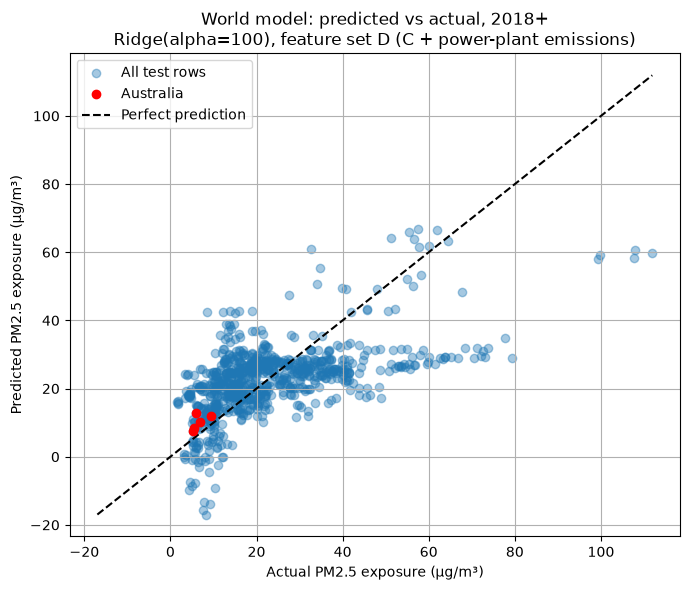

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_test, y_pred, alpha=0.4, label="All test rows")
ax.scatter(y_test[aus_mask], y_pred[aus_mask], color="red", label=TEST_COUNTRY, zorder=3)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(lims, lims, "k--", label="Perfect prediction")
ax.set(xlabel="Actual PM2.5 exposure (µg/m³)", ylabel="Predicted PM2.5 exposure (µg/m³)",
       title=f"World model: predicted vs actual, {SPLIT_YEAR}+\n{best_name}, feature set {best_fs}")
ax.legend(); ax.grid(True)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "world_model_pred_vs_actual.png"), dpi=150)
plt.show()

## Step 5c - Chart 2: residuals

A **residual** is the model's mistake: *actual minus predicted*. Each dot is one test row. Dots above the zero line are under-predictions; dots below are over-predictions.

A healthy model has dots scattered randomly around zero. A visible pattern (for example, the errors growing for high predictions) means the model is missing something systematic.

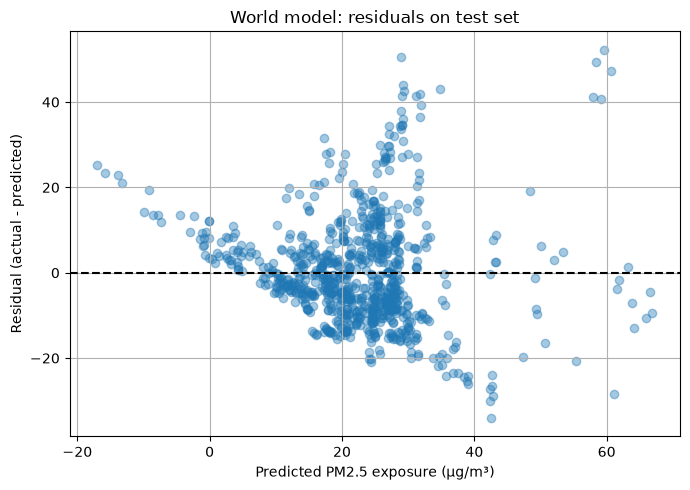

In [14]:
resid = y_test - y_pred
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_pred, resid, alpha=0.4)
ax.axhline(0, color="k", linestyle="--")
ax.set(xlabel="Predicted PM2.5 exposure (µg/m³)", ylabel="Residual (actual - predicted)",
       title="World model: residuals on test set")
ax.grid(True)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "world_model_residuals.png"), dpi=150)
plt.show()

## Step 5d - Chart 3: comparing the models in cross-validation

One panel per score, one bar per model and feature set. Each bar is the **average** across the 5 folds and the thin **error bar** shows the spread. **Blue bars use the original two shares, orange bars feature set C and green bars feature set D**, so the effect of each change is easy to see. If two bars are close and their error bars overlap, they are effectively tied.

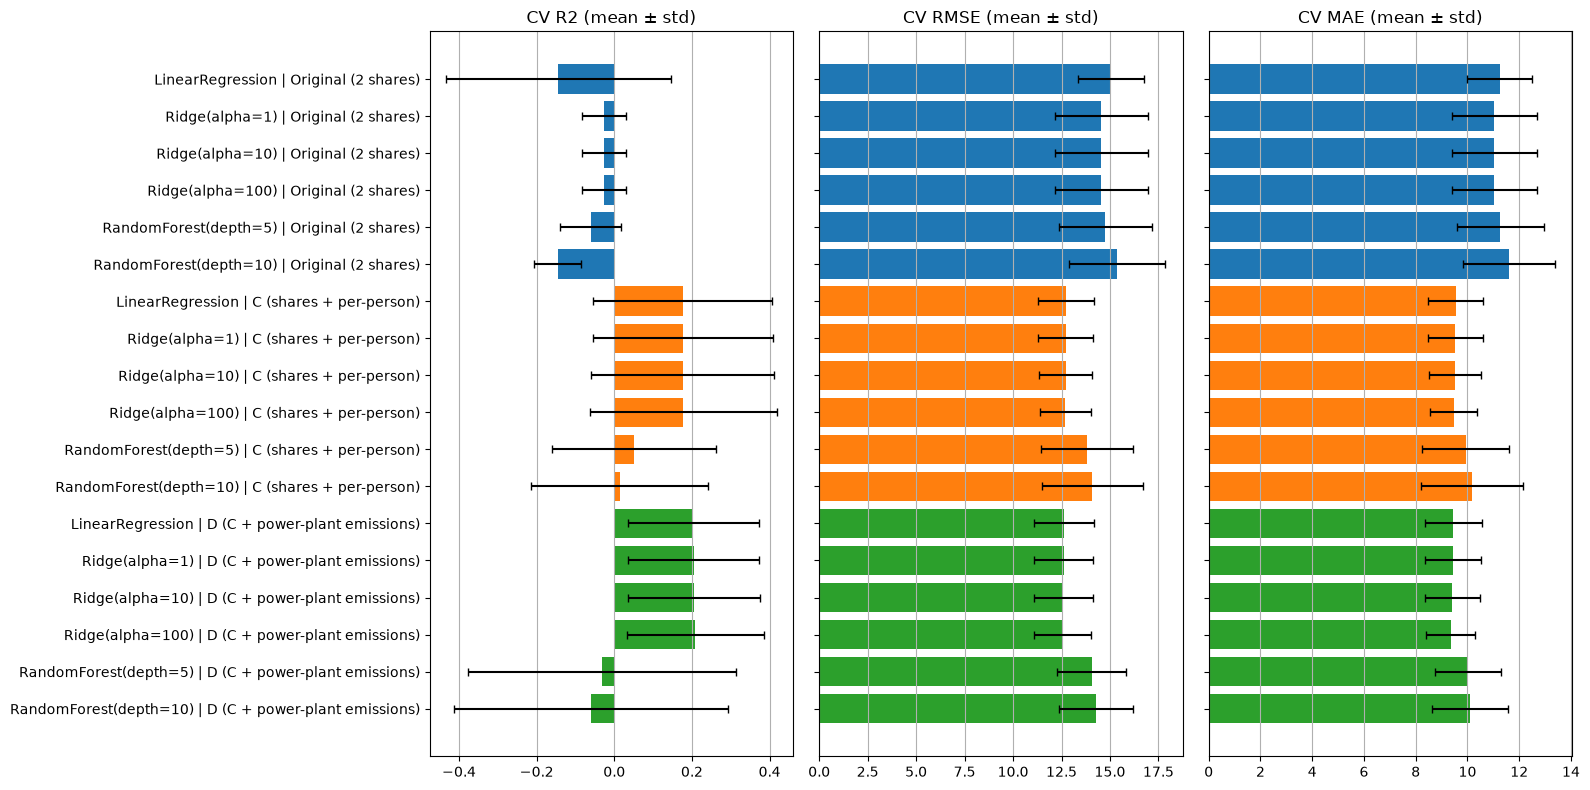

Saved metrics, model and plots to ../results/


In [15]:
FS_COLORS = dict(zip(FEATURE_SETS, ["tab:blue", "tab:orange", "tab:green"]))
labels = list(cv_folds)
colors = [FS_COLORS[label.split(" | ")[1]] for label in labels]
fig, axes = plt.subplots(1, 3, figsize=(16, 8), sharey=True)
for ax, metric in zip(axes, ["R2", "RMSE", "MAE"]):
    means = [cv_folds[l][metric].mean() for l in labels]
    stds = [cv_folds[l][metric].std() for l in labels]
    ax.barh(labels, means, xerr=stds, capsize=3, color=colors)
    ax.set_title(f"CV {metric} (mean ± std)")
    ax.grid(True, axis="x")
axes[0].invert_yaxis()
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "world_model_cv_comparison.png"), dpi=150)
plt.show()

print(f"Saved metrics, model and plots to {OUT_DIR}/")

# Part 6 - Which groups of features actually help? *(change 3)*

Feature set D has 19 inputs in five groups. Which ones does the model really need? An **ablation** answers this: start from set D, **remove one group at a time**, and re-score with the same cross-validation. A group that matters makes the score drop when it is removed; a group that doesn't matter leaves it unchanged.

To keep it fair, every variant uses the **same model** (Ridge, alpha = 100, the best straight-line model from Step 3c) and the **same 5 folds, grouped by country**, as Step 3b. Only the training years are used; the test set stays untouched.

| Group | Features | Idea behind it |
|---|---|---|
| **Source shares** (8) | % of electricity from coal, gas, oil, hydro, nuclear, solar, wind, biofuel | Different fuels pollute differently |
| **Per-person amounts** (5) | Coal, gas, oil and fossil electricity per person, and total electricity per person | How *much* fuel is burned, not just its share |
| **Power-plant SO₂** (2) | Grams per kWh and kg per person | Sulphur gas from coal and oil; turns into PM2.5 in the air |
| **Power-plant NOx** (2) | Grams per kWh and kg per person | Nitrogen gases from burning fuel; turn into PM2.5 in the air |
| **Power-plant PM2.5** (2) | Grams per kWh and kg per person | Particles released directly (e.g. fly ash, biomass burning) |

**How to read the table below:**

- **change vs D** is the drop (negative) or gain in average R² when the group is removed.
- **folds worse than D** counts how many of the 5 folds scored lower without the group. If it is 5 out of 5, the group helps consistently; 2 or 3 out of 5 is basically a coin toss. Always check the **size** of the change too: a group can be worse in every fold by a negligible amount.
- The **spread between folds (std) is large** here, because only 190 countries are split 5 ways and a few big, unusual countries can swing a fold. Look for patterns across folds, not small differences in the decimals.

In [16]:
ABLATION_MODEL = models["Ridge(alpha=100)"]   # the same pipeline as Step 3a
FEATURES_D = FEATURE_SETS["D (C + power-plant emissions)"]

def ablation_table(variants, reference):
    """CV R² and RMSE for each {name: feature list}, compared with the `reference` feature list."""
    def fold_scores(features):
        res = cross_validate(clone(ABLATION_MODEL), train[features], y_train, groups=groups_train,
                             cv=cv, scoring=scoring)
        return res["test_r2"], -res["test_rmse"]

    ref_r2, _ = fold_scores(reference)
    rows = []
    for name, features in variants.items():
        r2, rmse = fold_scores(features)
        rows.append({
            "variant": name,
            "n_features": len(features),
            "cv_r2_mean": r2.mean(), "cv_r2_std": r2.std(),
            "cv_rmse_mean": rmse.mean(),
            "change_vs_D": r2.mean() - ref_r2.mean(),
            "folds_worse_than_D": int((r2 < ref_r2).sum()),
            "fold_r2": [round(v, 2) for v in r2],
        })
    return pd.DataFrame(rows)

def features_without(features, *groups):
    """The feature list with every feature of the given groups removed."""
    removed = []
    for group in groups:
        removed.extend(group)
    kept = []
    for feature in features:
        if feature not in removed:
            kept.append(feature)
    return kept

GROUPS = {
    "source shares": SOURCE_SHARES,
    "per-person amounts": PER_PERSON,
    "power-plant SO2": ["power_so2_per_kwh", "power_so2_per_capita"],
    "power-plant NOx": ["power_nox_per_kwh", "power_nox_per_capita"],
    "power-plant PM2.5": ["power_pm25_per_kwh", "power_pm25_per_capita"],
}

variants = {"D (all groups)": FEATURES_D}
for group_name, group_features in GROUPS.items():
    variants[f"D minus {group_name}"] = features_without(FEATURES_D, group_features)
variants["D minus all 3 power-plant groups (= C)"] = features_without(
    FEATURES_D, GROUPS["power-plant SO2"], GROUPS["power-plant NOx"], GROUPS["power-plant PM2.5"])

ablation_main = ablation_table(variants, reference=FEATURES_D)
ablation_main.round(3)

,variant,n_features,cv_r2_mean,cv_r2_std,cv_rmse_mean,change_vs_D,folds_worse_than_D,fold_r2
0,D (all groups),19,0.209,0.177,12.551,0.000,0,"[0.35, -0.14, 0.3, 0.28, 0.26]"
1,D minus source shares,11,0.208,0.117,12.652,-0.000,4,"[0.31, -0.02, 0.24, 0.26, 0.25]"
2,D minus per-person amounts,14,-0.021,0.227,14.290,-0.230,5,"[0.22, -0.41, 0.17, 0.03, -0.11]"
3,D minus power-plant SO2,17,0.199,0.192,12.601,-0.010,3,"[0.36, -0.18, 0.29, 0.29, 0.24]"
4,D minus power-plant NOx,17,0.205,0.176,12.586,-0.004,5,"[0.34, -0.14, 0.29, 0.27, 0.26]"
5,D minus power-plant PM2.5,17,0.179,0.231,12.703,-0.030,4,"[0.33, -0.28, 0.29, 0.31, 0.25]"
6,D minus all 3 power-plant groups (= C),13,0.178,0.241,12.691,-0.031,4,"[0.34, -0.3, 0.28, 0.32, 0.25]"


## Step 6a - What the ablation shows

*(Numbers quoted here are from the run on 9 October 2026; the table above updates if the data or settings change.)*

- **Per-person amounts are the only group that clearly matters.** Without them average R² falls from about 0.21 to about 0, and all 5 folds get worse.
- **Source shares add nothing measurable.** Removing them leaves the average R² unchanged. (4 of 5 folds are very slightly worse, but one fold improves by about as much as the others lose, so the net effect is zero.)
- **The power-plant emissions help only a little.** All three groups together are worth about +0.03 R², which is smaller than the fold-to-fold spread (about 0.2). **Direct PM2.5 contributes the most, and SO₂ and NOx very little.** (NOx is worse in all 5 folds when removed, but by only about 0.004 R², far too small to matter.) That is the opposite of what the chemistry led us to expect (see the correction in the note at the top).
- Because the spread is so large, none of the small differences should be over-interpreted. The safe conclusions are the large ones: *per-person amounts matter; source shares and power-plant emissions matter little.*

## Step 6b - Is the per-person group just a stand-in for wealth?

Total electricity per person is partly a sign of how rich a country is, and richer countries tend to have cleaner air for many reasons unrelated to power plants. If the per-person group helps mostly because of wealth, then the model would be telling us about **wealth**, not about **electricity generation**.

The per-person group mixes two different ideas, so we split it:

- **(a) Total electricity per person** (`per_capita_electricity`): how much electricity a country uses *in total*. This is the more obvious wealth stand-in.
- **(b) Fuel-specific amounts** (coal, gas, oil, and all fossil electricity per person): how much *polluting* generation there is per person.

We score each part **on its own**, and **with it removed from D**. The "on its own" rows show what a part can do alone; the "removed" rows show how much D loses without it.

In [17]:
TOTAL_PER_PERSON = ["per_capita_electricity"]                                                # (a)
FUEL_PER_PERSON = ["coal_elec_per_capita", "gas_elec_per_capita",
                   "oil_elec_per_capita", "fossil_elec_per_capita"]                          # (b)

split_variants = {
    "D (all groups)": FEATURES_D,
    "(a) total electricity per person, ON ITS OWN": TOTAL_PER_PERSON,
    "(b) fuel-specific per person, ON ITS OWN": FUEL_PER_PERSON,
    "(a) + (b) together, ON ITS OWN": TOTAL_PER_PERSON + FUEL_PER_PERSON,
    "D minus (a) total electricity per person": features_without(FEATURES_D, TOTAL_PER_PERSON),
    "D minus (b) fuel-specific per person": features_without(FEATURES_D, FUEL_PER_PERSON),
    "D minus (a) and (b)": features_without(FEATURES_D, TOTAL_PER_PERSON, FUEL_PER_PERSON),
}
ablation_split = ablation_table(split_variants, reference=FEATURES_D)
display(ablation_split.round(3))

print("Correlation with PM2.5 exposure (training years):")
for column in TOTAL_PER_PERSON + ["fossil_elec_per_capita"]:
    print(f"  {column:26s} {train[column].corr(train[TARGET]):+.2f}")
print(f"Correlation between total and fossil electricity per person: "
      f"{train['per_capita_electricity'].corr(train['fossil_elec_per_capita']):+.2f}")

,variant,n_features,cv_r2_mean,cv_r2_std,cv_rmse_mean,change_vs_D,folds_worse_than_D,fold_r2
0,D (all groups),19,0.209,0.177,12.551,0.000,0,"[0.35, -0.14, 0.3, 0.28, 0.26]"
1,"(a) total electricity per person, ON ITS OWN",1,-0.016,0.062,14.526,-0.225,4,"[-0.02, -0.09, 0.06, 0.05, -0.08]"
2,"(b) fuel-specific per person, ON ITS OWN",4,0.141,0.131,13.171,-0.067,4,"[0.26, -0.1, 0.12, 0.26, 0.17]"
3,"(a) + (b) together, ON ITS OWN",5,0.187,0.168,12.749,-0.022,3,"[0.29, -0.14, 0.21, 0.33, 0.24]"
4,D minus (a) total electricity per person,18,0.180,0.154,12.830,-0.028,4,"[0.31, -0.12, 0.27, 0.24, 0.2]"
5,D minus (b) fuel-specific per person,15,0.002,0.244,14.091,-0.206,5,"[0.22, -0.44, 0.21, 0.09, -0.06]"
6,D minus (a) and (b),14,-0.021,0.227,14.290,-0.230,5,"[0.22, -0.41, 0.17, 0.03, -0.11]"


Correlation with PM2.5 exposure (training years):
  per_capita_electricity     -0.16
  fossil_elec_per_capita     +0.09
Correlation between total and fossil electricity per person: +0.53


## Step 6c - What the split shows

*(Numbers quoted here are from the run on 9 October 2026.)*

- **Total electricity per person has almost no predictive power on its own** (average R² about -0.02), and removing it from D costs only about 0.03. It is *not* what the per-person group's value comes from.
- **The fuel-specific amounts do the work.** On their own they reach an average R² of about 0.14; removing them from D drops it to about 0, with all 5 folds worse.
- So the worry that the per-person group is mainly a **wealth stand-in is not supported by this test**: the information is mostly in *how much coal, gas and oil is burned per person*, not in how much electricity is used overall. Total electricity per person is even negatively related to PM2.5 (richer countries are cleaner) while fossil electricity per person is positively related, and the model is using the second.
- **What this does not prove:** fuel burned per person is itself linked to industrialisation and income, so some wealth or development effect can remain. The model is also a straight line, so it can't capture more complicated interactions. Total electricity per person may still help a little by giving context: with it, the model can tell "lots of fossil power because the country uses lots of power" from "lots of fossil power in a country that uses little".

**Bottom line for the benchmark:** the world model's skill comes mainly from **how much fossil-fuel electricity each person's country generates**. Generation shares and power-plant emission estimates add little on top of that, and the final R² is still modest because most PM2.5 has non-electricity sources (Step 1d).

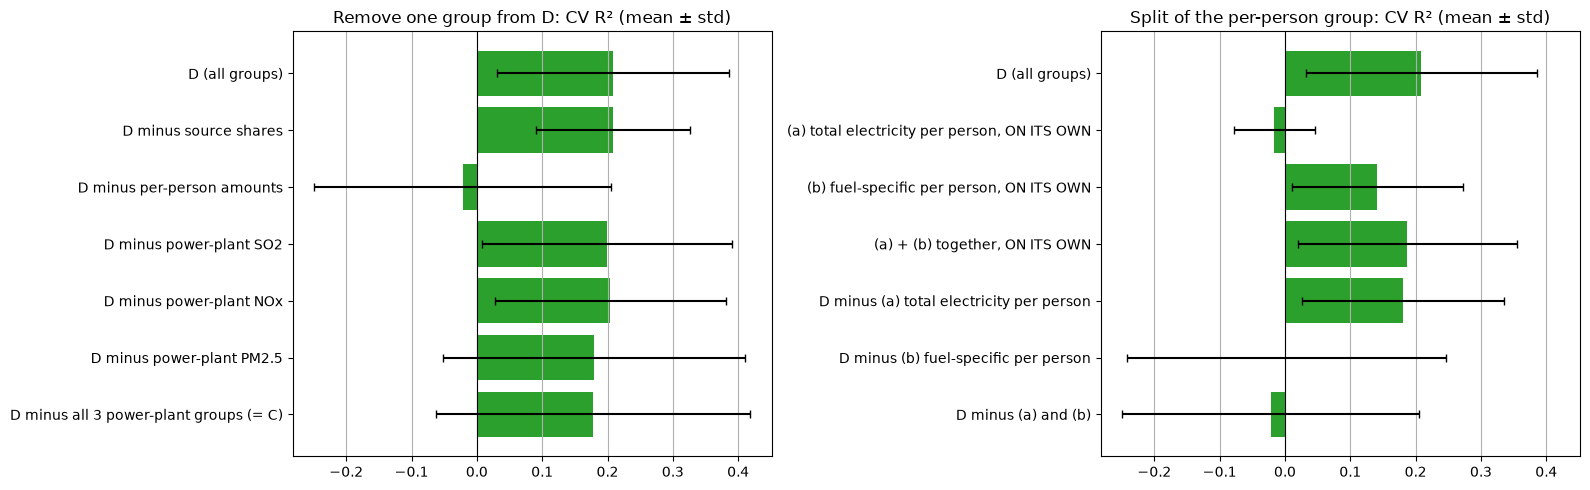

In [18]:
# Save the numbers and a chart of both tables
ablation_main["table"] = "remove one group from D"
ablation_split["table"] = "split of the per-person group"
pd.concat([ablation_main, ablation_split]).to_csv(os.path.join(OUT_DIR, "ablation_metrics.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True)
for ax, table, title in [(axes[0], ablation_main, "Remove one group from D"),
                         (axes[1], ablation_split, "Split of the per-person group")]:
    ax.barh(table["variant"], table["cv_r2_mean"], xerr=table["cv_r2_std"], capsize=3, color="tab:green")
    ax.axvline(0, color="k", linewidth=0.8)
    ax.invert_yaxis(); ax.grid(True, axis="x")
    ax.set_title(f"{title}: CV R² (mean ± std)")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "ablation.png"), dpi=150)
plt.show()

## Summary

- We trained on **190 countries, 1990-2017**, and tested on **2018-2022** (close to an 80/20 split). The 6 overlapping aggregate rows were removed.
- **Changes from the original plan:** besides the original two electricity shares, we added **feature set C** (each source's share separately, plus per-person electricity amounts) and **feature set D** (C plus power-plant SO₂, NOx and PM2.5 emissions from EDGAR). All three were compared. Part 6 shows that most of the gain over the original comes from the per-person fuel amounts, and that the power-plant emissions add only a little.
- Straight-line models (Linear Regression, Ridge) and a non-linear model (Random Forest) were compared with **5-fold cross-validation grouped by country**, with gap-filling and scaling done inside a Pipeline to avoid leakage.
- The best model and feature set by cross-validation was refit on all training data and tested **once** on the 2018+ data. Scores for **all countries** and for **Australia alone** are in Step 4 and in `results/world_model_metrics.csv`.
- This is the **benchmark**: a regional model is only worthwhile if it beats these numbers on the same test rows. Regional models should use the **same feature set** as the selected world model, so the comparison is fair.

**How to read the score:** power plants produce only a small share of directly emitted PM2.5 (Step 1d). Most comes from homes, industry, fires and natural dust. So electricity generation can only ever explain **part** of the differences in air pollution between countries, and a modest R² is the expected, honest answer to our question, not a modelling failure.

**Limitations to keep in mind**

- The model only knows about electricity generation and power-plant emissions. PM2.5 is also driven by things not in this data (desert dust, cooking with wood or charcoal, crop burning, traffic, weather).
- Electricity use per person partly reflects how wealthy a country is, so some of the predictive power of feature sets C and D may come from wealth rather than from electricity itself. Part 6 checks this: total electricity per person adds little, and the fuel-specific amounts carry the signal, although those too may partly reflect how developed a country is.
- EDGAR emissions are modelled estimates, not measurements, and about 4% of rows have no power-sector entry (filled with the median).
- Australia has very few test rows, so its scores are unreliable.
- The test period is short (five years, and 2022 is only partly covered).

# Part 7 - A second question: does a country's air change when *its* electricity changes? *(change 4)*

Parts 1-6 compare **countries with each other**: "do countries that burn more coal have dirtier air?" The trouble is that countries differ in countless ways that have nothing to do with electricity: Niger has desert dust, India has widespread cooking on wood fires, Iceland has neither. These differences swamp the electricity signal.

This part asks a sharper question by comparing **each country with itself over time**: *"In the years when a country burned more coal than usual, was its air dirtier than usual?"* Things like deserts, climate and cooking habits barely change from year to year within a country, so they drop out of the comparison.

## Step 7a - Express everything relative to each country's own average

For every country we work out its **average over the training years** (before 2018) for PM2.5 and for every feature. Then each row is turned into a **deviation**: *this year's value minus the country's own average*. For example, if Australia's average PM2.5 over 1990-2017 was 8 and in 2010 it was 7, its 2010 deviation is -1.

The averages are computed from **training years only**, and then also used for the test years, so nothing from 2018+ leaks into the setup.

In [19]:
WITHIN_FEATURES = FEATURE_SETS["D (C + power-plant emissions)"]
within_cols = WITHIN_FEATURES + ["year", TARGET]

# each country's own average over the TRAINING years only (no test-period information)
country_means = train.groupby("country")[within_cols].mean()

def relative_to_own_average(frame):
    """Each value minus that country's training-period average."""
    means = country_means.reindex(frame["country"]).set_index(frame.index)
    out = frame[within_cols] - means[within_cols]
    out["country"] = frame["country"]
    return out

train_w = relative_to_own_average(train)
test_w = relative_to_own_average(test)
print(f"Typical size of a country's year-to-year swings in PM2.5 (std of deviations): "
      f"{train_w[TARGET].std():.2f} µg/m³ (training years)")
train_w.head()

Typical size of a country's year-to-year swings in PM2.5 (std of deviations): 3.57 µg/m³ (training years)


,coal_share_elec,gas_share_elec,oil_share_elec,hydro_share_elec,nuclear_share_elec,solar_share_elec,wind_share_elec,biofuel_share_elec,coal_elec_per_capita,gas_elec_per_capita,...,per_capita_electricity,power_so2_per_kwh,power_so2_per_capita,power_nox_per_kwh,power_nox_per_capita,power_pm25_per_kwh,power_pm25_per_capita,year,PM2.5 Exposure,country
0,0.0,0.0,12.111889,-11.128833,0.0,-0.983111,0.0,0.0,0.0,0.0,...,-9.3375,-10.790823,-0.412113,-4.239937,-0.170112,-1.344608,-0.045312,-8.5,7.758817,Afghanistan
1,0.0,0.0,-6.677111,7.660167,0.0,-0.983111,0.0,0.0,0.0,0.0,...,-3.4205,-11.324611,-0.384283,-4.890767,-0.166321,-1.241155,-0.041672,-7.5,6.348201,Afghanistan
2,0.0,0.0,-3.090111,4.073167,0.0,-0.983111,0.0,0.0,0.0,0.0,...,-0.5305,-12.918570,-0.416791,-5.621754,-0.180842,-1.295733,-0.042903,-6.5,8.623069,Afghanistan
3,0.0,0.0,11.047889,-10.064833,0.0,-0.983111,0.0,0.0,0.0,0.0,...,8.1225,-12.488255,-0.353249,-5.521172,-0.154557,-1.262776,-0.040323,-5.5,7.651954,Afghanistan
4,0.0,0.0,15.147889,-14.164833,0.0,-0.983111,0.0,0.0,0.0,0.0,...,4.3985,-13.110591,-0.398024,-5.612580,-0.167900,-1.268117,-0.041169,-4.5,6.396293,Afghanistan


## Step 7b - Compare three sets of inputs with cross-validation

PM2.5 levels in many countries have been drifting steadily up or down over the years for many reasons (new vehicle standards, industrial growth, etc.). If we're not careful, electricity could get credit for a trend it didn't cause. So we compare:

| Inputs | Question it answers |
|---|---|
| **Time trend only** (`year`) | How much of a country's changes is just a steady drift over time? This is the **baseline** to beat. |
| **Electricity only** (feature set D) | How much can changes in electricity generation and power-plant emissions explain on their own? |
| **Electricity + time trend** | Do electricity changes explain anything **beyond** the steady drift? |

If "electricity + time trend" scores clearly better than "time trend only", changes in electricity generation do help explain changes in a country's air quality.

We use the same cross-validation as before (5 folds, grouped by country) and two of the models from Step 3a. Note that R² here measures something different from Part 3: the share of each country's **ups and downs around its own average** that is explained, not differences between countries.

In [20]:
WITHIN_SETS = {
    "Time trend only": ["year"],
    "Electricity only": WITHIN_FEATURES,
    "Electricity + time trend": WITHIN_FEATURES + ["year"],
}
within_models = {name: models[name] for name in ["Ridge(alpha=10)", "RandomForest(depth=5)"]}

within_results, within_folds = cross_validate_all(train_w, TARGET, WITHIN_SETS, within_models)
within_results.round(3)

,model,feature_set,cv_r2_mean,cv_r2_std,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_mae_std
0,Ridge(alpha=10),Time trend only,0.146,0.110,3.272,0.419,2.207,0.213
1,RandomForest(depth=5),Time trend only,0.164,0.112,3.239,0.431,2.162,0.211
2,Ridge(alpha=10),Electricity only,0.061,0.117,3.426,0.394,2.361,0.284
3,RandomForest(depth=5),Electricity only,0.156,0.070,3.257,0.377,2.204,0.211
4,Ridge(alpha=10),Electricity + time trend,0.149,0.104,3.259,0.345,2.233,0.234
5,RandomForest(depth=5),Electricity + time trend,0.184,0.080,3.202,0.391,2.140,0.218


## Step 7c - Choose the best and test it once

As in Part 4: pick the best combination by cross-validation RMSE, refit it on all training years, and score it **once** on the 2018+ test years.

In [21]:
best_w = within_results.loc[within_results["cv_rmse_mean"].idxmin()]
best_w_name, best_w_set = best_w["model"], best_w["feature_set"]
best_w_features = WITHIN_SETS[best_w_set]
within_model = clone(within_models[best_w_name]).fit(train_w[best_w_features], train_w[TARGET])
y_pred_w = within_model.predict(test_w[best_w_features])
test_w_m = metrics(test_w[TARGET], y_pred_w)

trend = within_results[within_results["feature_set"] == "Time trend only"]["cv_r2_mean"].max()
both = within_results[within_results["feature_set"] == "Electricity + time trend"]["cv_r2_mean"].max()
print(f"Best by CV RMSE: {best_w_name} with '{best_w_set}'")
print(f"Test set (2018+): " + ", ".join(f"{k}={v:.4f}" for k, v in test_w_m.items()))
print(f"\nBest CV R2 with time trend only:          {trend:.3f}")
print(f"Best CV R2 with electricity + time trend:  {both:.3f}  (extra explained by electricity: {both - trend:+.3f})")

is_best_w = ((within_results["model"] == best_w_name) & (within_results["feature_set"] == best_w_set)).to_numpy()
for k, v in test_w_m.items():
    within_results[f"test_{k}"] = np.where(is_best_w, v, np.nan)
within_results["selected"] = is_best_w
within_results.to_csv(os.path.join(OUT_DIR, "within_country_metrics.csv"), index=False)

Best by CV RMSE: RandomForest(depth=5) with 'Electricity + time trend'
Test set (2018+): r2=0.1785, rmse=3.4996, mae=2.5466

Best CV R2 with time trend only:          0.164
Best CV R2 with electricity + time trend:  0.184  (extra explained by electricity: +0.020)


## Step 7d - Charts

**Left:** cross-validation R² for each combination. Compare the **grey** bars (time trend only) with the **green** ones (electricity + time trend): the gap between them is what electricity adds.

**Right:** three example countries over time. The solid line is the real PM2.5; the dashed line is the model's estimate (its predicted deviation added back to the country's own average). The shaded area is the test period the model never saw; the years before it were used for training, so the fit there is expected to look good.

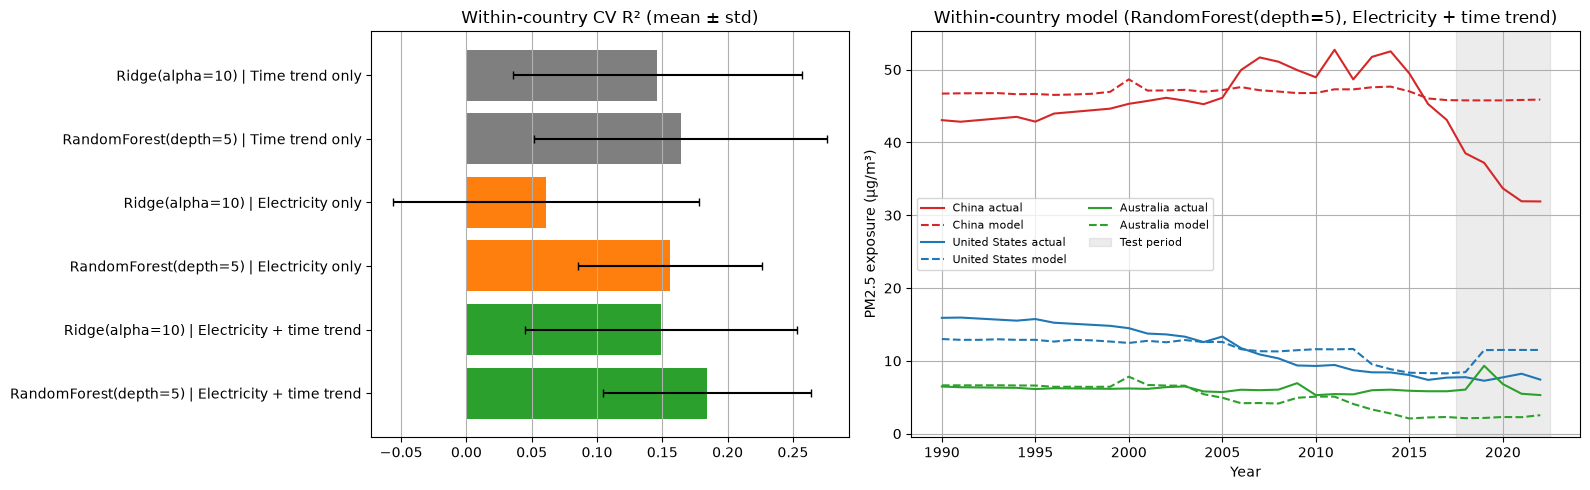

In [22]:
SET_COLORS = {"Time trend only": "tab:grey", "Electricity only": "tab:orange",
              "Electricity + time trend": "tab:green"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.4]})

labels_w = list(within_folds)
ax1.barh(labels_w, [within_folds[l]["R2"].mean() for l in labels_w],
         xerr=[within_folds[l]["R2"].std() for l in labels_w], capsize=3,
         color=[SET_COLORS[l.split(" | ")[1]] for l in labels_w])
ax1.invert_yaxis(); ax1.grid(True, axis="x")
ax1.set_title("Within-country CV R² (mean ± std)")

for country, color in zip(["China", "United States", TEST_COUNTRY], ["tab:red", "tab:blue", "tab:green"]):
    rows = df[df["country"] == country].sort_values("year")
    estimate = within_model.predict(relative_to_own_average(rows)[best_w_features]) + country_means.loc[country, TARGET]
    ax2.plot(rows["year"], rows[TARGET], color=color, label=f"{country} actual")
    ax2.plot(rows["year"], estimate, color=color, linestyle="--", label=f"{country} model")
ax2.axvspan(SPLIT_YEAR - 0.5, df["year"].max() + 0.5, color="grey", alpha=0.15, label="Test period")
ax2.set(xlabel="Year", ylabel="PM2.5 exposure (µg/m³)",
        title=f"Within-country model ({best_w_name}, {best_w_set})")
ax2.legend(fontsize=8, ncol=2); ax2.grid(True)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "within_country.png"), dpi=150)
plt.show()

## Step 7e - What Part 7 tells us

- If **"electricity + time trend" is only slightly better than "time trend only"**, most of the change in a country's air quality over time is a general drift, and changes in its electricity generation explain only a little on top. That matches Step 1d: power plants are a small slice of PM2.5.
- If the gap is **large**, countries that cleaned up their electricity generation (e.g. phased out coal or fitted scrubbers) saw their air improve more than the general trend, which would be strong support for the link we're studying.
- Either way, this comparison is **fairer to electricity** than Parts 1-6, because each country is compared only with itself, so deserts, climate and cooking habits can't mask the effect.

**Limitations:** a country's yearly swings in PM2.5 are small (a few µg/m³), so the numbers are noisy; weather in a given year (e.g. bushfire seasons in Australia) can cause swings electricity can't explain; and this still shows **association**, not proof of cause and effect.

Results are saved to `results/within_country_metrics.csv` and `results/within_country.png`.